# Confusión temporal: predicción frente a intervención
## Resumen
En un DGP conocido sin efecto causal de X sobre Y, la regresión de Y sobre X rezagado rechaza ausencia de asociación en todas las réplicas n=500. Eso no es error del contraste de asociación: el error sería interpretarlo como causalidad. Controlar el confusor correcto recupera β y una tasa de rechazo cercana a α.
## Contexto y métodos
$$Z_t\sim N(0,1),\quad X_t=0.8Z_{t-1}+u^X_t,\quad Y_t=\beta X_{t-1}+0.8Z_{t-2}+u^Y_t.$$
Innovaciones independientes, $u^X,u^Y\sim N(0,0.5^2)$. Las filas $(X_{t-1},Z_{t-2},Y_t)$ son IID en este caso especial; no se simula un VAR con autocorrelación general.
OLS sin control converge a $\beta+0.64/0.89$, pero bajo intervención emparejada $do(X_{t-1}\leftarrow X_{t-1}+\delta)$ el cambio de Y es $\beta\delta$. Es una identidad del SCM conocido, no una estimación observacional.
Para test de un coeficiente: $F=[(RSS_R-RSS_U)/1]/[RSS_U/(n-p)]\sim F_{1,n-p}$ bajo nulidad, rango completo y errores gaussianos IID independientes del diseño **completo**. Con control correcto esas condiciones se cumplen. No se afirman para la ablación de lag erróneo, que expone Z adyacentes.
### Supuestos e identificabilidad
Confusor observado sin error y lag correcto permiten interpretar β dentro de este SCM. Omitirlo, medirlo con ruido o elegir otro lag no da identificación causal. Ningún rechazo predictivo certifica intervención.
## Datos
Semilla20261025;200 réplicas independientes por n/β. Cuatro métodos comparten cada dataset, por lo que comparaciones entre métodos son pareadas. No son4800 datasets independientes.

In [1]:
import json,csv
from pathlib import Path
from IPython.display import display,Image
summary=json.loads(Path('results/summary.json').read_text())
summary['config']

Out[0]: 
{'seed': 20261025,
 'sample_sizes': [100, 500, 2000],
 'replicates': 200,
 'effects': [0.0, 0.3],
 'alpha': 0.05,
 'loading_x': 0.8,
 'loading_y': 0.8,
 'noise_x_sd': 0.5,
 'noise_y_sd': 0.5,
 'proxy_noise_sd': 1.0,
 'thresholds': {'controlled_null_rejection_max': 0.1,
  'controlled_power_min_at_n500': 0.8,
  'controlled_bias_abs_max_at_n2000': 0.03}}


## Resultados
La tabla siguiente muestra solo n=500. Los intervalos MC de rechazo son Clopper–Pearson sobre200 réplicas por método, no intervalos del efecto causal.

In [2]:
summary['selected_n500']

Out[0]: 
[{'n': 500,
  'effect': 0.0,
  'method': 'omitted',
  'replicates': 200,
  'rejection_rate': 1.0,
  'mc_95_low': 0.9817246596448638,
  'mc_95_high': 1,
  'mean_slope': 0.7212384513537694,
  'mean_bias_vs_structural': 0.7212384513537694,
  'structural_ci_coverage': 0.0,
  'median_seconds': 0.0007211285000039425,
  'max_python_bytes': 47066},
 {'n': 500,
  'effect': 0.0,
  'method': 'observed_correct_lag',
  'replicates': 200,
  'rejection_rate': 0.045,
  'mc_95_low': 0.020780422227004353,
  'mc_95_high': 0.08370268807585404,
  'mean_slope': -0.006266827561014102,
  'mean_bias_vs_structural': -0.006266827561014102,
  'structural_ci_coverage': 0.955,
  'median_seconds': 0.0007301675000235264,
  'max_python_bytes': 67267},
 {'n': 500,
  'effect': 0.0,
  'method': 'observed_wrong_lag',
  'replicates': 200,
  'rejection_rate': 1.0,
  'mc_95_low': 0.9817246596448638,
  'mc_95_high': 1,
  'mean_slope': 0.7211119163580478,
  'mean_bias_vs_structural': 0.7211119163580478,
  'structural_

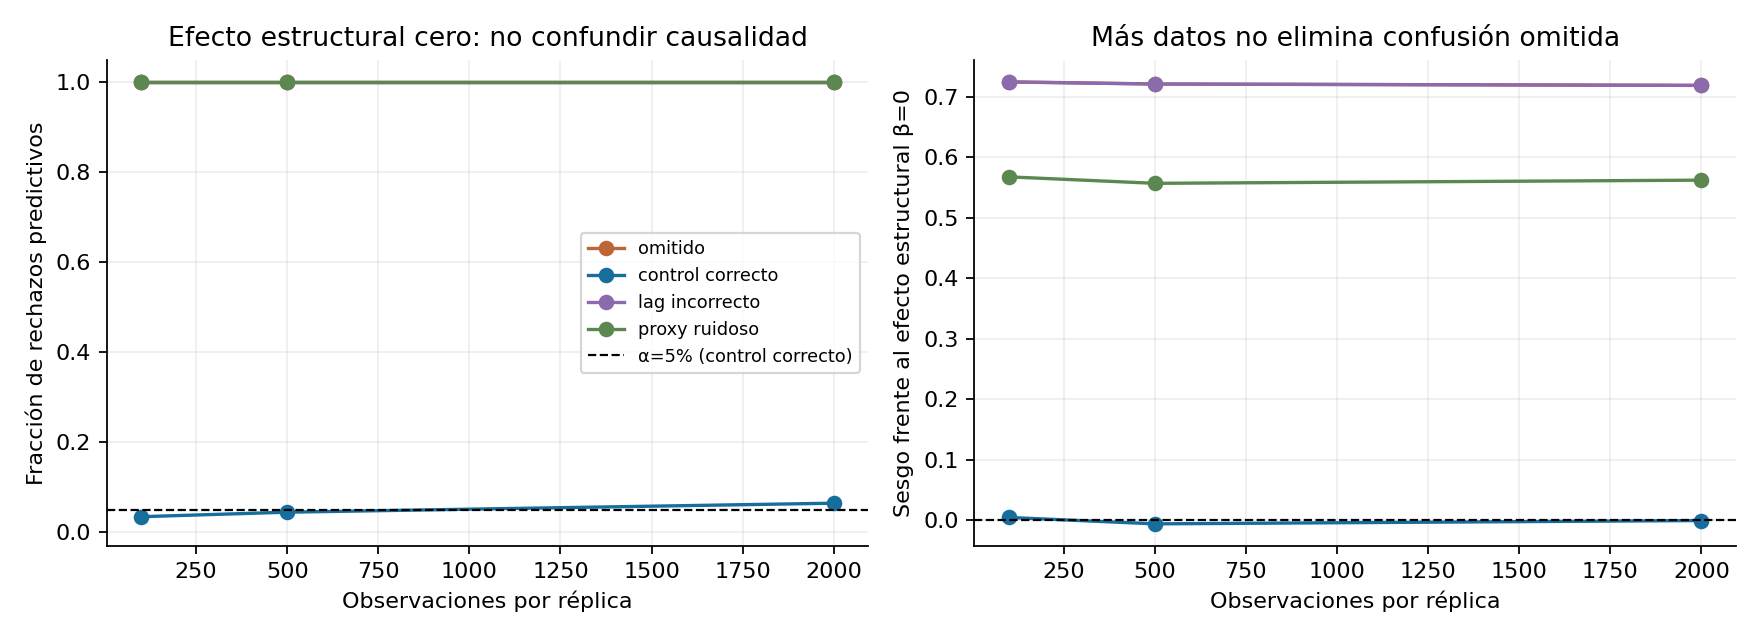

In [3]:
display(Image(filename='results/audit.png'))

### Intervención y controles negativos
Proxy ruidoso no equivale a observar el confusor; añadir un control equivocado tampoco cierra el backdoor. La comparación omitida estima otra cantidad poblacional, no un estimador sesgado de su propio parámetro de asociación.

In [4]:
from src.confounding import generate,lag_test,paired_intervention
import numpy as np
s=generate(500,0,12)
assert np.array_equal(paired_intervention(s,1),s.y)
print('Asociación:',lag_test(s.y,s.x_lag))
print('Control correcto:',lag_test(s.y,s.x_lag,s.z_lag2))
print('Intervención SCM nula:',float(np.mean(paired_intervention(s,1)-s.y)))

Asociación: TestResult(slope=0.7255807205225362, standard_error=0.033381712961371685, f_statistic=472.44823637184027, p_value=3.651662024690058e-74, ci_low=0.6599943677491048, ci_high=0.7911670732959676, degrees_freedom=498)
Control correcto: TestResult(slope=-0.03145607257758554, standard_error=0.045000787633811684, f_statistic=0.488617217320259, p_value=0.4848717631268397, ci_low=-0.11987130769377433, ci_high=0.05695916253860325, degrees_freedom=497)
Intervención SCM nula: 0.0


## Comprobaciones
Tests incluyen oracle scipy.linregress, identidad F=t², residualización FWL, invariancia afín y errores de rango/varianza. El umbral registrado no es prueba de calibración universal.

In [5]:
summary['checks']

Out[0]: 
{'null_rejection_at_most_threshold': True,
 'power_at_least_threshold_n500plus': True,
 'bias_at_n2000_below_threshold': True}


## Conclusiones
Más datos concentra la asociación omitida alrededor de0.719 aunque β=0. La mejora local es un banco de falsación reproducible; no un algoritmo nuevo de causal discovery. Componente S2 limitado; nonlinearidad, feedback, PCMCI y datos reales siguen pendientes. Fuentes primarias verificadas y BibTeX en fuentes.md/referencias.bib; informe.md documenta14 puntos, alternativas descartadas y límites.